   # Deliverable 1: a feed-forward network for artwork classification (11 genres)

   Same method as `04_01_feed_forward_style.ipynb`, on the genre subset: 11 genres, about 2 300 training images.
   The eight tries are run again, and the final network is chosen on the validation set of the genres.

In [4]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import json
import time

# Our own package: the same data pipeline and training functions for every model
from museum_guide.data import prepare_subset
from museum_guide.training import count_parameters, evaluate, fit

# Fix the random seed so that every run gives the same results
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load, split, standardise and batch the genre subset (takes about a minute)
genre = prepare_subset("genre")
print("device:", device, "| classes:", len(genre["classes"]), "| train batches:", len(genre["train_loader"]))

device: cpu | classes: 11 | train batches: 37


# Deliverable 1: a feed-forward network for artwork classification

## Design choices

| Element | Choice | Why |
|---|---|---|
| Input | 3 x 128 x 128 image, flattened to 49 152 values | default size of the course script (`--size 128`) |
| Hidden layers | 2 layers, 256 then 128 neurons | a simple network, close to the course examples |
| Activation | ReLU | default for hidden layers (TP05) |
| Initialisation | He | recommended with ReLU (TP05, Part D) |
| Output and loss | one logit per class + `CrossEntropyLoss` | standard multi-class recipe (TP05, TP06) |
| Optimiser | Adam, learning rate 1e-3 | usual default of Adam (TP06) |
| Training | 30 epochs, mini-batches of 64 | long enough to see overfitting appear (TP06) |
| Regularisation | none | added and measured in deliverable 2 |

In [5]:
def make_mlp(n_classes, image_shape=(3, 128, 128), hidden_sizes=(256, 128)):
    """Build a feed-forward network (MLP) for colour images, as in TP05 and TP06.

    Args:
        n_classes: number of classes to predict (27 styles or 11 genres).
        image_shape: shape of one input image, (channels, height, width).
        hidden_sizes: number of neurons of each hidden layer.

    Returns:
        An nn.Sequential that maps a batch (B, 3, 128, 128) to (B, n_classes) logits.
    """
    # Turn each image into a vector: (B, 3, 128, 128) -> (B, 49152)
    layers = [nn.Flatten()]
    n_in = image_shape[0] * image_shape[1] * image_shape[2]
    for n_out in hidden_sizes:
        # One hidden layer followed by a ReLU (TP05, Part C)
        layers += [nn.Linear(n_in, n_out), nn.ReLU()]
        n_in = n_out
    # Output layer: one score (logit) per class, no softmax since CrossEntropyLoss applies it
    layers.append(nn.Linear(n_in, n_classes))
    model = nn.Sequential(*layers)

    # He initialisation, recommended for ReLU networks (TP05 Part D, TP06 exercise 21)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model


torch.manual_seed(0)
model = make_mlp(n_classes=len(genre["classes"])).to(device)
print(model)
print("parameters:", count_parameters(model))

# Check the output shape on one mini-batch
xb, yb = next(iter(genre["train_loader"]))
print("output:", tuple(model(xb.to(device)).shape))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=49152, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=11, bias=True)
)
parameters: 12617483
output: (64, 11)


In [6]:
# Start training 

N_EPOCHS = 30
LEARNING_RATE = 1e-3

# Start again from a fresh network, so that the run does not depend on the cells above
torch.manual_seed(0)
genre_model = make_mlp(n_classes=len(genre["classes"])).to(device)

# The loss and the optimiser chosen together (see the design choices table)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(genre_model.parameters(), lr=LEARNING_RATE)

# Train for N_EPOCHS and keep the history of the metrics for the plots
genre_history = fit(
    genre_model, genre["train_loader"], genre["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)

epoch  1 | train loss 14.715 acc 0.256 | val loss 18.948 acc 0.143 | 1.6 s
epoch  2 | train loss 15.250 acc 0.326 | val loss 22.347 acc 0.173 | 1.4 s
epoch  3 | train loss 4.334 acc 0.466 | val loss 9.908 acc 0.153 | 1.4 s
epoch  4 | train loss 4.008 acc 0.509 | val loss 10.082 acc 0.153 | 1.4 s
epoch  5 | train loss 3.941 acc 0.541 | val loss 10.789 acc 0.153 | 1.6 s
epoch  6 | train loss 2.684 acc 0.548 | val loss 8.080 acc 0.177 | 1.4 s
epoch  7 | train loss 1.439 acc 0.649 | val loss 6.622 acc 0.183 | 1.4 s
epoch  8 | train loss 1.211 acc 0.705 | val loss 6.550 acc 0.210 | 1.4 s
epoch  9 | train loss 1.504 acc 0.649 | val loss 6.516 acc 0.175 | 1.4 s
epoch 10 | train loss 1.144 acc 0.697 | val loss 6.191 acc 0.169 | 1.7 s
epoch 11 | train loss 1.305 acc 0.686 | val loss 6.981 acc 0.185 | 1.5 s
epoch 12 | train loss 0.790 acc 0.747 | val loss 5.520 acc 0.196 | 1.5 s
epoch 13 | train loss 0.744 acc 0.779 | val loss 5.966 acc 0.224 | 1.5 s
epoch 14 | train loss 0.741 acc 0.776 | val l

In [7]:
genre_history["val_acc"]

[0.1431451612903226,
 0.17338709677419356,
 0.1532258064516129,
 0.1532258064516129,
 0.1532258064516129,
 0.1774193548387097,
 0.18346774193548387,
 0.20967741935483872,
 0.17540322580645162,
 0.1693548387096774,
 0.18548387096774194,
 0.19556451612903225,
 0.22379032258064516,
 0.20766129032258066,
 0.22580645161290322,
 0.19556451612903225,
 0.23588709677419356,
 0.20766129032258066,
 0.1814516129032258,
 0.20967741935483872,
 0.23588709677419356,
 0.22580645161290322,
 0.19153225806451613,
 0.21370967741935484,
 0.13911290322580644,
 0.20766129032258066,
 0.23387096774193547,
 0.2217741935483871,
 0.2318548387096774,
 0.22580645161290322]

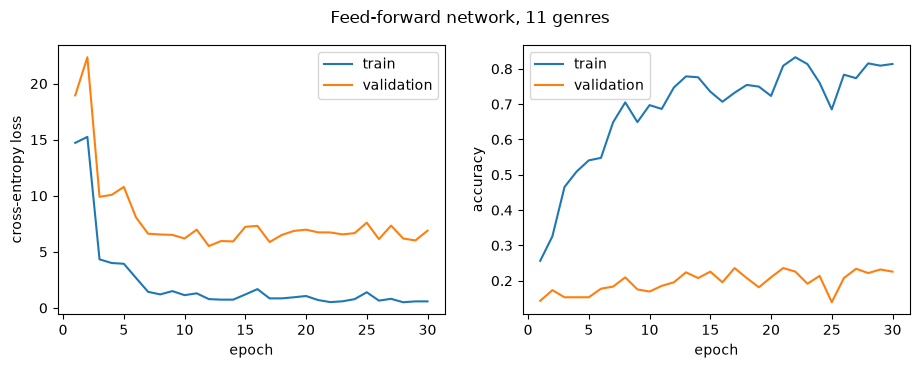

In [8]:
def plot_history(history, title=""):
    """Plot the loss and accuracy curves of a training run, train versus validation, as in TP06.

    Args:
        history: the dictionary returned by fit.
        title: title of the figure.
    """
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

    # Left: the loss (lower is better)
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].legend()

    # Right: the accuracy (higher is better)
    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].legend()

    fig.suptitle(title)
    plt.show()


plot_history(genre_history, "Feed-forward network, 11 genres")

## Try 2: a simpler network (one hidden layer of 128 neurons)

Same sequence of tries as for the styles (`04_01_feed_forward_style.ipynb`), where the first network
(12.6 M weights) learnt the training images by heart.

| Element | Try 1 | Try 2 |
|---|---|---|
| Hidden layers | 256 then 128 neurons | **1 layer of 128 neurons** |
| Weights | 12.6 M | **6.3 M** |
| Learning rate | 1e-3 | 1e-3 |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 6293003
epoch  1 | train loss 16.134 acc 0.318 | val loss 24.384 acc 0.210 | 0.8 s
epoch  2 | train loss 11.139 acc 0.407 | val loss 21.693 acc 0.194 | 0.8 s
epoch  3 | train loss 10.458 acc 0.439 | val loss 22.898 acc 0.145 | 0.7 s
epoch  4 | train loss 10.284 acc 0.496 | val loss 26.393 acc 0.165 | 0.7 s
epoch  5 | train loss 5.462 acc 0.617 | val loss 20.813 acc 0.210 | 0.8 s
epoch  6 | train loss 5.565 acc 0.630 | val loss 22.711 acc 0.177 | 0.8 s
epoch  7 | train loss 6.639 acc 0.603 | val loss 23.722 acc 0.167 | 0.8 s
epoch  8 | train loss 4.572 acc 0.687 | val loss 23.743 acc 0.204 | 0.9 s
epoch  9 | train loss 7.922 acc 0.648 | val loss 29.974 acc 0.185 | 0.8 s
epoch 10 | train loss 5.257 acc 0.699 | val loss 27.854 acc 0.155 | 1.0 s
epoch 11 | train loss 2.800 acc 0.748 | val loss 24.000 acc 0.173 | 1.1 s
epoch 12 | train loss 3.122 acc 0.803 | val loss 26.269 acc 0.192 | 0.9 s
epoch 13 | train loss 2.767 acc 0.808 | val loss 26.096 acc 0.188 | 1.0 s
epoch 14 | tra

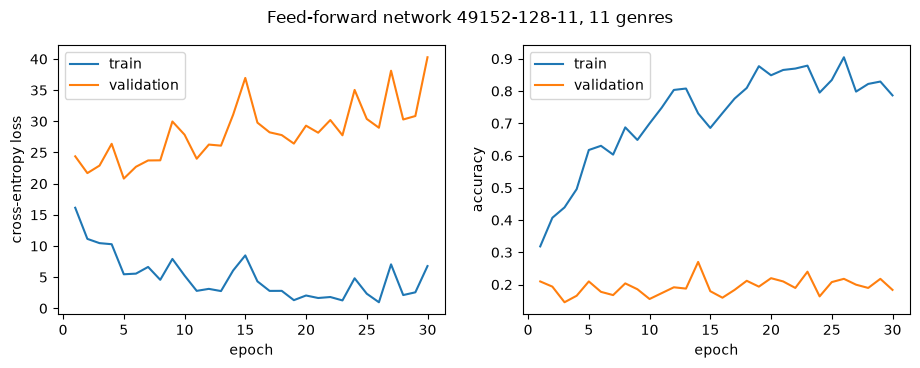

In [9]:
# Second try: a simpler network with one hidden layer of 128 neurons (option A),
# as for the styles
torch.manual_seed(0)
genre_model_a = make_mlp(n_classes=len(genre["classes"]), hidden_sizes=(128,)).to(device)
print("parameters:", count_parameters(genre_model_a))

# Same loss and same optimiser settings as the first try, only the network changes
optimizer = torch.optim.Adam(genre_model_a.parameters(), lr=LEARNING_RATE)
genre_history_a = fit(
    genre_model_a, genre["train_loader"], genre["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)
plot_history(genre_history_a, "Feed-forward network 49152-128-11, 11 genres")

## Try 3: a basic network (one hidden layer of 32 neurons)

As for the styles, we test whether a much smaller network is enough.

| Element | Try 2 | Try 3 |
|---|---|---|
| Hidden layers | 1 layer of 128 neurons | **1 layer of 32 neurons** |
| Weights | 6.3 M | **1.6 M** |
| Learning rate | 1e-3 | 1e-3 |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 1573259
epoch  1 | train loss 9.540 acc 0.217 | val loss 13.113 acc 0.133 | 0.3 s
epoch  2 | train loss 7.557 acc 0.256 | val loss 12.805 acc 0.145 | 0.2 s
epoch  3 | train loss 5.508 acc 0.299 | val loss 11.371 acc 0.127 | 0.3 s
epoch  4 | train loss 7.721 acc 0.292 | val loss 16.738 acc 0.135 | 0.3 s
epoch  5 | train loss 6.035 acc 0.366 | val loss 14.873 acc 0.151 | 0.3 s
epoch  6 | train loss 4.005 acc 0.451 | val loss 13.643 acc 0.188 | 0.3 s
epoch  7 | train loss 3.587 acc 0.437 | val loss 12.953 acc 0.163 | 0.3 s
epoch  8 | train loss 3.146 acc 0.470 | val loss 13.503 acc 0.200 | 0.3 s
epoch  9 | train loss 2.565 acc 0.481 | val loss 13.179 acc 0.185 | 0.3 s
epoch 10 | train loss 5.443 acc 0.421 | val loss 17.275 acc 0.177 | 0.3 s
epoch 11 | train loss 3.626 acc 0.473 | val loss 15.860 acc 0.192 | 0.3 s
epoch 12 | train loss 3.019 acc 0.485 | val loss 15.159 acc 0.171 | 0.3 s
epoch 13 | train loss 3.882 acc 0.476 | val loss 16.616 acc 0.151 | 0.3 s
epoch 14 | train l

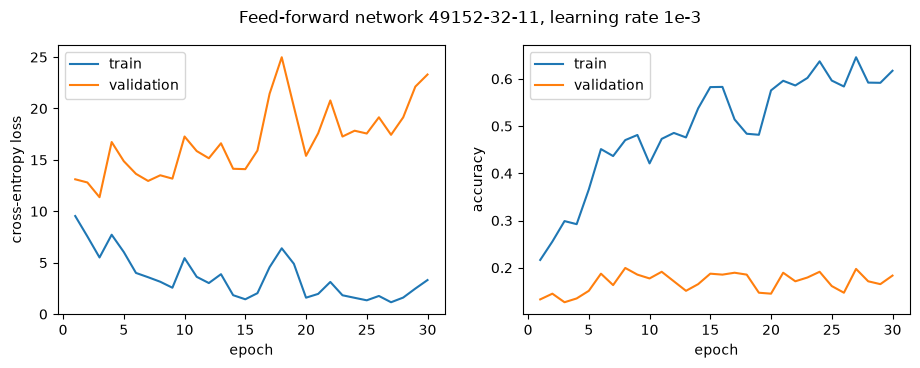

In [10]:
# Third try: a basic network with one hidden layer of 32 neurons.
# Only the size changes: the learning rate stays at 1e-3.
torch.manual_seed(0)
genre_model_c = make_mlp(n_classes=len(genre["classes"]), hidden_sizes=(32,)).to(device)
print("parameters:", count_parameters(genre_model_c))

optimizer = torch.optim.Adam(genre_model_c.parameters(), lr=1e-3)
genre_history_c = fit(
    genre_model_c, genre["train_loader"], genre["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)
plot_history(genre_history_c, "Feed-forward network 49152-32-11, learning rate 1e-3")

## Tries 4 to 6: the same three networks with a learning rate 10 times smaller

On the styles, a learning rate of 1e-3 gave very high losses with jumps on the training curves:
each neuron of the first layer has 49 152 inputs, so the small moves of all its weights add up to
large jumps. We train the same three networks with a learning rate of 1e-4, and change nothing else.

In [11]:
def train_genre_mlp(hidden_sizes, learning_rate, n_epochs=N_EPOCHS):
    """Build a fresh feed-forward network for the genres and train it with Adam.

    Args:
        hidden_sizes: number of neurons of each hidden layer, for example (128,).
        learning_rate: learning rate of Adam.
        n_epochs: number of epochs.

    Returns:
        (model, history): the trained network and the history returned by fit.
    """
    # Same seed for every try: same initial weights and same order of the mini-batches
    torch.manual_seed(0)
    model = make_mlp(n_classes=len(genre["classes"]), hidden_sizes=hidden_sizes).to(device)
    print("parameters:", count_parameters(model))

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = fit(
        model, genre["train_loader"], genre["val_loader"], loss_fn, optimizer, n_epochs, device=device
    )
    return model, history

### Try 4: two hidden layers (256 then 128 neurons), learning rate 1e-4

| Element | Try 1 | Try 4 |
|---|---|---|
| Hidden layers | 256 then 128 neurons | 256 then 128 neurons |
| Weights | 12.6 M | 12.6 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 12617483
epoch  1 | train loss 2.361 acc 0.369 | val loss 3.257 acc 0.226 | 1.5 s
epoch  2 | train loss 2.025 acc 0.469 | val loss 3.540 acc 0.183 | 1.4 s
epoch  3 | train loss 1.281 acc 0.635 | val loss 3.208 acc 0.196 | 1.5 s
epoch  4 | train loss 1.465 acc 0.643 | val loss 3.865 acc 0.202 | 1.5 s
epoch  5 | train loss 0.838 acc 0.774 | val loss 3.421 acc 0.206 | 1.5 s
epoch  6 | train loss 0.894 acc 0.774 | val loss 3.931 acc 0.226 | 1.5 s
epoch  7 | train loss 0.642 acc 0.815 | val loss 3.767 acc 0.190 | 1.5 s
epoch  8 | train loss 0.806 acc 0.807 | val loss 4.197 acc 0.222 | 1.5 s
epoch  9 | train loss 0.440 acc 0.872 | val loss 3.750 acc 0.214 | 1.5 s
epoch 10 | train loss 0.465 acc 0.878 | val loss 3.899 acc 0.188 | 1.5 s
epoch 11 | train loss 0.627 acc 0.849 | val loss 4.431 acc 0.194 | 1.5 s
epoch 12 | train loss 0.305 acc 0.919 | val loss 3.951 acc 0.228 | 1.5 s
epoch 13 | train loss 0.231 acc 0.941 | val loss 3.993 acc 0.232 | 1.5 s
epoch 14 | train loss 0.147 ac

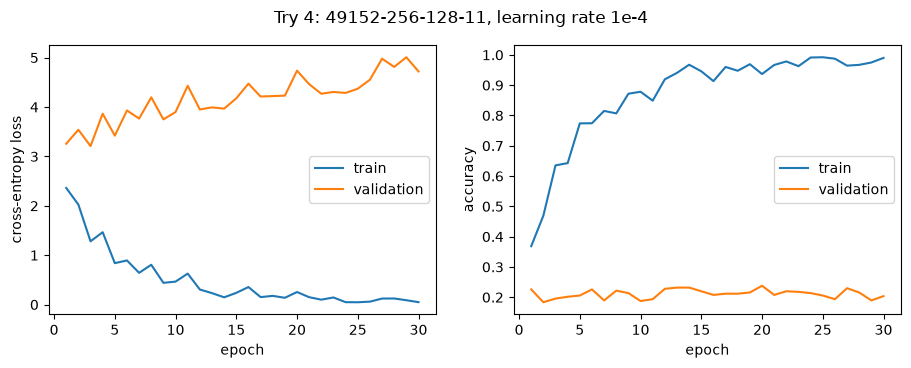

In [12]:
# Try 4: the network of try 1 with a learning rate 10 times smaller
genre_model_4, genre_history_4 = train_genre_mlp(hidden_sizes=(256, 128), learning_rate=1e-4)
plot_history(genre_history_4, "Try 4: 49152-256-128-11, learning rate 1e-4")

### Try 5: one hidden layer of 128 neurons, learning rate 1e-4

| Element | Try 2 | Try 5 |
|---|---|---|
| Hidden layers | 1 layer of 128 neurons | 1 layer of 128 neurons |
| Weights | 6.3 M | 6.3 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 6293003
epoch  1 | train loss 2.443 acc 0.336 | val loss 3.411 acc 0.175 | 0.8 s
epoch  2 | train loss 2.239 acc 0.470 | val loss 4.107 acc 0.230 | 0.8 s
epoch  3 | train loss 1.805 acc 0.523 | val loss 4.048 acc 0.171 | 0.7 s
epoch  4 | train loss 1.424 acc 0.600 | val loss 3.923 acc 0.192 | 0.7 s
epoch  5 | train loss 0.969 acc 0.744 | val loss 3.583 acc 0.264 | 0.7 s
epoch  6 | train loss 0.923 acc 0.744 | val loss 3.884 acc 0.177 | 0.8 s
epoch  7 | train loss 0.786 acc 0.796 | val loss 3.884 acc 0.171 | 0.9 s
epoch  8 | train loss 0.520 acc 0.872 | val loss 3.658 acc 0.212 | 0.8 s
epoch  9 | train loss 0.788 acc 0.826 | val loss 4.226 acc 0.208 | 0.8 s
epoch 10 | train loss 0.348 acc 0.917 | val loss 3.769 acc 0.248 | 0.8 s
epoch 11 | train loss 0.364 acc 0.916 | val loss 3.956 acc 0.218 | 0.8 s
epoch 12 | train loss 0.308 acc 0.933 | val loss 3.993 acc 0.230 | 0.8 s
epoch 13 | train loss 0.513 acc 0.897 | val loss 4.628 acc 0.190 | 0.8 s
epoch 14 | train loss 0.443 acc

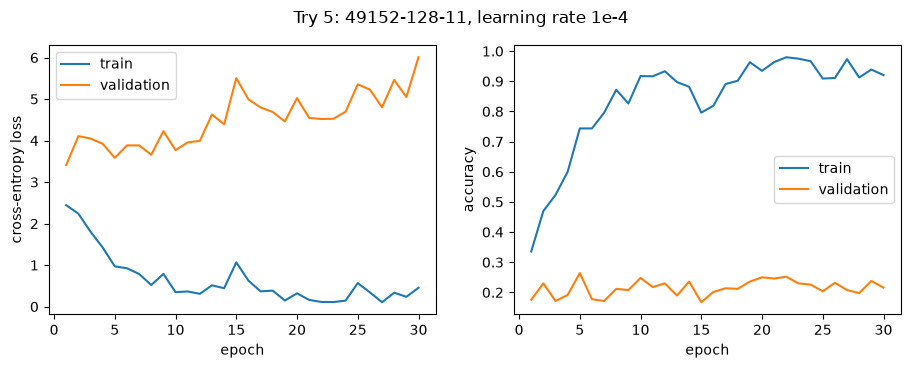

In [13]:
# Try 5: the network of try 2 with a learning rate 10 times smaller
genre_model_5, genre_history_5 = train_genre_mlp(hidden_sizes=(128,), learning_rate=1e-4)
plot_history(genre_history_5, "Try 5: 49152-128-11, learning rate 1e-4")

### Try 6: one hidden layer of 32 neurons, learning rate 1e-4

| Element | Try 3 | Try 6 |
|---|---|---|
| Hidden layers | 1 layer of 32 neurons | 1 layer of 32 neurons |
| Weights | 1.6 M | 1.6 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 1573259
epoch  1 | train loss 2.508 acc 0.253 | val loss 3.129 acc 0.183 | 0.3 s
epoch  2 | train loss 1.919 acc 0.378 | val loss 2.839 acc 0.224 | 0.3 s
epoch  3 | train loss 1.642 acc 0.472 | val loss 2.859 acc 0.216 | 0.3 s
epoch  4 | train loss 1.656 acc 0.473 | val loss 3.252 acc 0.200 | 0.3 s
epoch  5 | train loss 1.484 acc 0.546 | val loss 3.356 acc 0.200 | 0.3 s
epoch  6 | train loss 1.115 acc 0.661 | val loss 3.066 acc 0.222 | 0.3 s
epoch  7 | train loss 1.268 acc 0.631 | val loss 3.422 acc 0.198 | 0.3 s
epoch  8 | train loss 0.934 acc 0.720 | val loss 3.138 acc 0.238 | 0.3 s
epoch  9 | train loss 0.926 acc 0.731 | val loss 3.389 acc 0.196 | 0.3 s
epoch 10 | train loss 1.101 acc 0.689 | val loss 3.736 acc 0.198 | 0.4 s
epoch 11 | train loss 0.774 acc 0.791 | val loss 3.376 acc 0.252 | 0.4 s
epoch 12 | train loss 0.640 acc 0.820 | val loss 3.399 acc 0.190 | 0.3 s
epoch 13 | train loss 0.592 acc 0.841 | val loss 3.380 acc 0.228 | 0.3 s
epoch 14 | train loss 0.647 acc

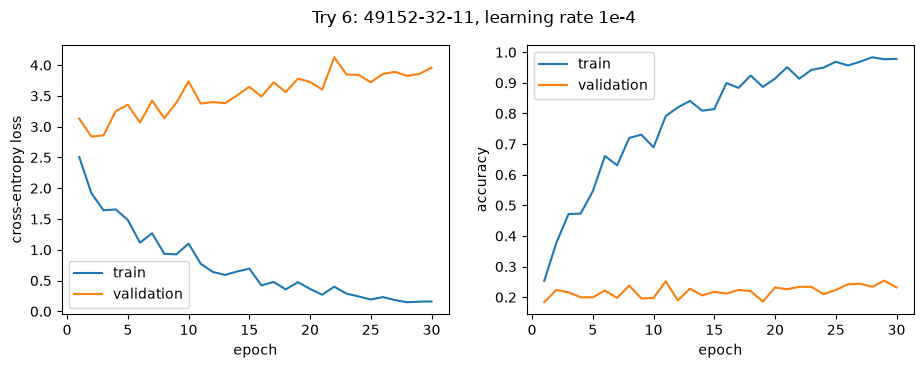

In [14]:
# Try 6: the network of try 3 with a learning rate 10 times smaller
genre_model_6, genre_history_6 = train_genre_mlp(hidden_sizes=(32,), learning_rate=1e-4)
plot_history(genre_history_6, "Try 6: 49152-32-11, learning rate 1e-4")


## Tries 7 and 8: average pooling before the dense network

All the previous networks flatten the 49 152 pixel values: too many inputs for about 5 200
training images, and the dense layer does not know which pixels are neighbours (course S07, slide 4).
We keep the network of try 4 (256 then 128 neurons, learning rate 1e-4) and add one layer in front of it:
`nn.AvgPool2d(k)` replaces each block of k x k pixels by its mean (course S07, slide 12).
It has no weight to learn, so the model stays a dense network, with k ** 2 times fewer inputs.

| Element | Try 4 | Try 7 | Try 8 |
|---|---|---|---|
| Pooling before the network | none | **4 x 4 average** | **8 x 8 average** |
| Image seen by the dense layers | 128 x 128 | 32 x 32 | 16 x 16 |
| Inputs | 49 152 | 3 072 | 768 |
| Everything else | 256-128, ReLU, He, Adam lr 1e-4, 30 epochs | unchanged | unchanged |

In [15]:
def make_pooled_mlp(n_classes, pool_size, hidden_sizes=(256, 128)):
    """Build an average pooling layer followed by the feed-forward network of make_mlp.

    Args:
        n_classes: number of classes to predict (27 genres or 11 genres).
        pool_size: each block of pool_size x pool_size pixels is replaced by its mean.
        hidden_sizes: number of neurons of each hidden layer of the dense network.

    Returns:
        An nn.Sequential that maps a batch (B, 3, 128, 128) to (B, n_classes) logits.
    """
    # Size of the image after pooling, for example 128 // 4 = 32
    pooled_side = 128 // pool_size
    return nn.Sequential(
        # Summarise each block of pixels by its mean (course S07, slide 12): no weight to learn
        nn.AvgPool2d(pool_size),
        # The unchanged dense network, built for the smaller pooled image
        make_mlp(n_classes, image_shape=(3, pooled_side, pooled_side), hidden_sizes=hidden_sizes),
    )


def train_genre_pooled_mlp(pool_size, learning_rate=1e-4, hidden_sizes=(256, 128), n_epochs=N_EPOCHS):
    """Build a fresh pooled network for the genres and train it with Adam, like train_genre_mlp.

    Returns:
        (model, history): the trained network and the history returned by fit.
    """
    # Same seed as the other tries: same initial weights and same order of the mini-batches
    torch.manual_seed(0)
    model = make_pooled_mlp(len(genre["classes"]), pool_size, hidden_sizes).to(device)
    print("parameters:", count_parameters(model))

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = fit(
        model, genre["train_loader"], genre["val_loader"], loss_fn, optimizer, n_epochs, device=device
    )
    return model, history


# Quick check of the number of weights, before any training
for pool in [4, 8]:
    print(f"pool {pool}: {count_parameters(make_pooled_mlp(len(genre['classes']), pool)):,} parameters")

pool 4: 821,003 parameters
pool 8: 231,179 parameters


parameters: 821003
epoch  1 | train loss 2.037 acc 0.293 | val loss 2.266 acc 0.226 | 0.3 s
epoch  2 | train loss 1.822 acc 0.381 | val loss 2.232 acc 0.234 | 0.2 s
epoch  3 | train loss 1.669 acc 0.462 | val loss 2.215 acc 0.232 | 0.2 s
epoch  4 | train loss 1.562 acc 0.511 | val loss 2.216 acc 0.248 | 0.2 s
epoch  5 | train loss 1.450 acc 0.574 | val loss 2.211 acc 0.236 | 0.2 s
epoch  6 | train loss 1.340 acc 0.620 | val loss 2.214 acc 0.246 | 0.3 s
epoch  7 | train loss 1.262 acc 0.650 | val loss 2.229 acc 0.254 | 0.2 s
epoch  8 | train loss 1.170 acc 0.699 | val loss 2.229 acc 0.254 | 0.3 s
epoch  9 | train loss 1.108 acc 0.731 | val loss 2.248 acc 0.254 | 0.2 s
epoch 10 | train loss 1.051 acc 0.757 | val loss 2.289 acc 0.220 | 0.2 s
epoch 11 | train loss 0.977 acc 0.786 | val loss 2.287 acc 0.258 | 0.3 s
epoch 12 | train loss 0.905 acc 0.811 | val loss 2.301 acc 0.240 | 0.2 s
epoch 13 | train loss 0.864 acc 0.813 | val loss 2.332 acc 0.266 | 0.2 s
epoch 14 | train loss 0.805 acc 

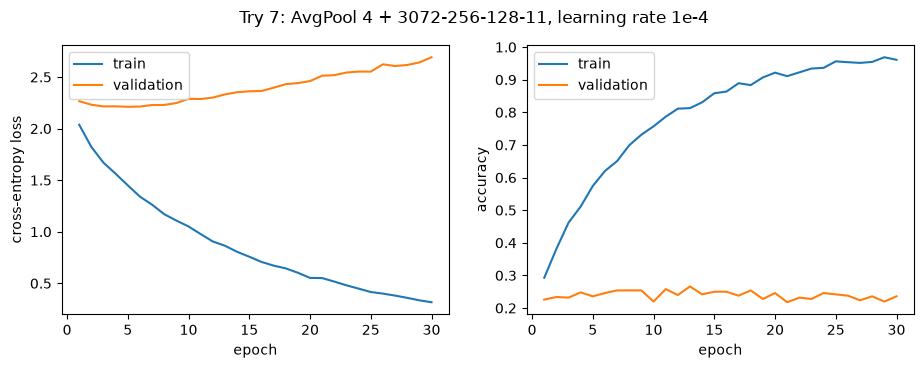

In [16]:
# Try 7: 4 x 4 average pooling (the network sees a 32 x 32 image), then the network of try 4
genre_model_7, genre_history_7 = train_genre_pooled_mlp(pool_size=4)
plot_history(genre_history_7, "Try 7: AvgPool 4 + 3072-256-128-11, learning rate 1e-4")

parameters: 231179
epoch  1 | train loss 2.315 acc 0.200 | val loss 2.407 acc 0.185 | 0.2 s
epoch  2 | train loss 2.164 acc 0.243 | val loss 2.320 acc 0.210 | 0.2 s
epoch  3 | train loss 2.064 acc 0.278 | val loss 2.284 acc 0.224 | 0.2 s
epoch  4 | train loss 1.990 acc 0.301 | val loss 2.272 acc 0.212 | 0.2 s
epoch  5 | train loss 1.930 acc 0.324 | val loss 2.253 acc 0.218 | 0.2 s
epoch  6 | train loss 1.877 acc 0.353 | val loss 2.249 acc 0.224 | 0.2 s
epoch  7 | train loss 1.828 acc 0.380 | val loss 2.257 acc 0.218 | 0.2 s
epoch  8 | train loss 1.781 acc 0.404 | val loss 2.248 acc 0.230 | 0.2 s
epoch  9 | train loss 1.738 acc 0.422 | val loss 2.251 acc 0.234 | 0.2 s
epoch 10 | train loss 1.701 acc 0.438 | val loss 2.250 acc 0.228 | 0.2 s
epoch 11 | train loss 1.665 acc 0.456 | val loss 2.247 acc 0.240 | 0.2 s
epoch 12 | train loss 1.624 acc 0.481 | val loss 2.234 acc 0.236 | 0.1 s
epoch 13 | train loss 1.590 acc 0.495 | val loss 2.235 acc 0.242 | 0.2 s
epoch 14 | train loss 1.560 acc 

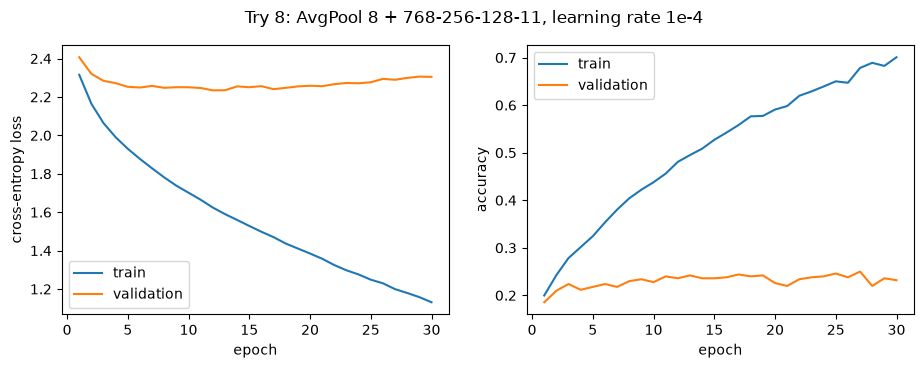

In [17]:
# Try 8: 8 x 8 average pooling (the network sees a 16 x 16 image), then the network of try 4
genre_model_8, genre_history_8 = train_genre_pooled_mlp(pool_size=8)
plot_history(genre_history_8, "Try 8: AvgPool 8 + 768-256-128-11, learning rate 1e-4")

## Summary of the eight tries

For each try: the epoch with the best validation accuracy, and that accuracy.
Chance level with 11 genres: about 0.09.

In [18]:
# One line per try: (number, hidden layers, learning rate, pooling, history returned by fit).
# The history variables are the ones created in the cells above.
tries = [
    (1, "2 layers: 256, 128", 1e-3, "none", genre_history),
    (2, "1 layer: 128", 1e-3, "none", genre_history_a),
    (3, "1 layer: 32", 1e-3, "none", genre_history_c),
    (4, "2 layers: 256, 128", 1e-4, "none", genre_history_4),
    (5, "1 layer: 128", 1e-4, "none", genre_history_5),
    (6, "1 layer: 32", 1e-4, "none", genre_history_6),
    (7, "2 layers: 256, 128", 1e-4, "4 x 4 average", genre_history_7),
    (8, "2 layers: 256, 128", 1e-4, "8 x 8 average", genre_history_8),
]

rows = []
for number, layers, learning_rate, pooling, history in tries:
    # Best validation accuracy over the 30 epochs, and the epoch where it was reached (counted from 1)
    best_acc = max(history["val_acc"])
    best_epoch = history["val_acc"].index(best_acc) + 1
    rows.append({
        "try": number,
        "hidden layers": layers,
        "learning rate": learning_rate,
        "pooling": pooling,
        "best epoch": best_epoch,
        "best val accuracy": round(best_acc, 3),
    })

# One row per try, indexed by the try number
genre_summary = pd.DataFrame(rows).set_index("try")
genre_summary.sort_values("best val accuracy", ascending=False)

,hidden layers,learning rate,pooling,best epoch,best val accuracy
try,,,,,
2,1 layer: 128,0.0010,none,14,0.270
7,"2 layers: 256, 128",0.0001,4 x 4 average,13,0.266
5,1 layer: 128,0.0001,none,5,0.264
6,1 layer: 32,0.0001,none,29,0.254
8,"2 layers: 256, 128",0.0001,8 x 8 average,27,0.250
4,"2 layers: 256, 128",0.0001,none,20,0.238
1,"2 layers: 256, 128",0.0010,none,17,0.236
3,1 layer: 32,0.0010,none,8,0.200


## Final network: try 7 trained for 13 epochs

Tries 2, 7, 5, 6 and 8 reach 25 to 27 % on validation: with about 500 validation images
(uncertainty of about ± 2 points), these differences are within the noise.
We keep try 7 (4 x 4 average pooling, then 256-128, learning rate 1e-4), for three reasons:
it has 8 times fewer weights than try 2, its learning rate gives a stable training,
and it is the same network as the final network of the styles.
Its best validation accuracy is reached at epoch 13: we train it again for 13 epochs.
With the same seed, these 13 epochs are the same as the first 13 epochs of try 7.

parameters: 821003
epoch  1 | train loss 2.037 acc 0.293 | val loss 2.266 acc 0.226 | 0.2 s
epoch  2 | train loss 1.822 acc 0.381 | val loss 2.232 acc 0.234 | 0.2 s
epoch  3 | train loss 1.669 acc 0.462 | val loss 2.215 acc 0.232 | 0.2 s
epoch  4 | train loss 1.562 acc 0.511 | val loss 2.216 acc 0.248 | 0.2 s
epoch  5 | train loss 1.450 acc 0.574 | val loss 2.211 acc 0.236 | 0.2 s
epoch  6 | train loss 1.340 acc 0.620 | val loss 2.214 acc 0.246 | 0.2 s
epoch  7 | train loss 1.262 acc 0.650 | val loss 2.229 acc 0.254 | 0.2 s
epoch  8 | train loss 1.170 acc 0.699 | val loss 2.229 acc 0.254 | 0.2 s
epoch  9 | train loss 1.108 acc 0.731 | val loss 2.248 acc 0.254 | 0.2 s
epoch 10 | train loss 1.051 acc 0.757 | val loss 2.289 acc 0.220 | 0.2 s
epoch 11 | train loss 0.977 acc 0.786 | val loss 2.287 acc 0.258 | 0.2 s
epoch 12 | train loss 0.905 acc 0.811 | val loss 2.301 acc 0.240 | 0.2 s
epoch 13 | train loss 0.864 acc 0.813 | val loss 2.332 acc 0.266 | 0.2 s
validation accuracy at epoch 13:

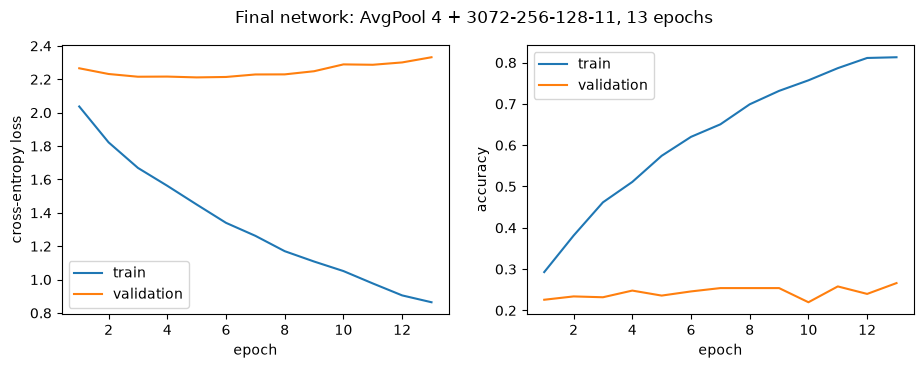

In [19]:
FINAL_EPOCHS = 13  # epoch of the best validation accuracy of try 7 on the genres (see the summary table)

# Same settings as try 7, only the number of epochs changes
final_model, final_history = train_genre_pooled_mlp(pool_size=4, n_epochs=FINAL_EPOCHS)

# Check: same seed, so the last validation accuracy must equal the one of try 7 at epoch 12
print(
    f"validation accuracy at epoch {FINAL_EPOCHS}: {final_history['val_acc'][-1]:.3f} "
    f"(try 7 at the same epoch: {genre_history_7['val_acc'][FINAL_EPOCHS - 1]:.3f})"
)
plot_history(final_history, f"Final network: AvgPool 4 + 3072-256-128-11, {FINAL_EPOCHS} epochs")

## Final evaluation on the test set (once)

The final network is now measured once on the test images, never used for training
nor for choosing the model or the number of epochs.

In [20]:
# Folder of the team's figures (created if it does not exist yet)
FIG_DIR = Path("..") / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The final network, measured ONCE on the test images
test_loss, test_acc = evaluate(final_model, genre["test_loader"], loss_fn, device=device)
n_classes = len(genre["classes"])
print(
    f"TEST accuracy = {test_acc:.3f} "
    f"| validation accuracy {final_history['val_acc'][-1]:.3f} | chance {1 / n_classes:.3f}"
)

# Predicted class of every test image (the test loader is not shuffled, so the order is kept)
final_model.eval()
with torch.no_grad():
    y_pred = torch.cat(
        [final_model(xb.to(device)).argmax(dim=1).cpu() for xb, _ in genre["test_loader"]]
    ).numpy()

# True class of the same test images, in the same order
y_true = genre["y"][torch.as_tensor(genre["test_idx"])].numpy()

TEST accuracy = 0.269 | validation accuracy 0.266 | chance 0.091


## Confusion matrix

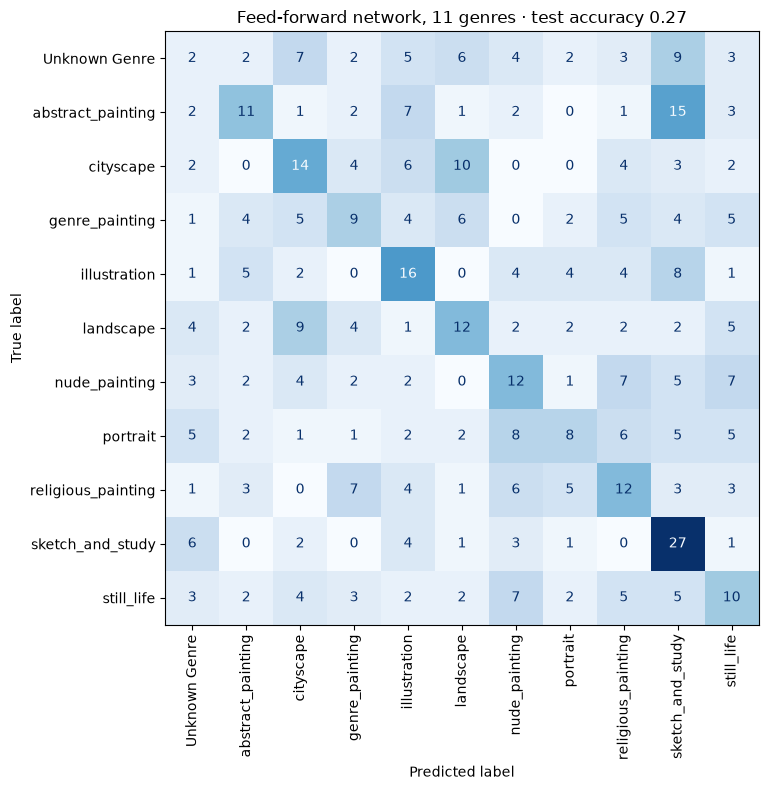

In [21]:
class_names = genre["classes"]

# Entry [i, j] = number of test images of true class i predicted as class j (TP05, exercise 7)
cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))

fig, ax = plt.subplots(figsize=(9, 8))  # 11 classes: a smaller figure than for the 27 styles
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues"
)
ax.set_title(f"Feed-forward network, 11 genres · test accuracy {test_acc:.2f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "mlp_genre_confusion_test.png", dpi=150)  # saved for the slides
plt.show()

## Accuracy per genre and most frequent error

In [22]:
# Accuracy of each genre: correct predictions divided by the number of test images of that genre
per_class = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(class_names, per_class), key=lambda pair: -pair[1]):  # best genres first
    print(f"  {name:28s} {acc:.2f}")

# Most frequent mistake: the largest entry outside the diagonal (TP05, exercise 7)
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
i, j = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
print(f"most frequent mistake: true '{class_names[i]}' predicted as '{class_names[j]}' ({off_diagonal[i, j]} times)")

  sketch_and_study             0.60
  illustration                 0.36
  cityscape                    0.31
  landscape                    0.27
  nude_painting                0.27
  religious_painting           0.27
  abstract_painting            0.24
  still_life                   0.22
  genre_painting               0.20
  portrait                     0.18
  Unknown Genre                0.04
most frequent mistake: true 'abstract_painting' predicted as 'sketch_and_study' (15 times)


## Cost for the kiosk and results file

As in `05_resnet`, the final network classifies one image on one CPU thread (a modest kiosk):
median time of 50 runs, after 5 warm-up runs. The results are saved in `results/mlp_genre.json`,
with the same keys as the other models of the team, for the final comparison.

In [23]:
# --- Cost for the kiosk: time to classify ONE image on ONE CPU thread (as in 05_resnet) ---
cpu_model = final_model.to("cpu").eval()
x_one = genre["X"][:1]  # one standardised image, shape (1, 3, 128, 128)

previous_threads = torch.get_num_threads()
torch.set_num_threads(1)  # simulate a modest kiosk CPU
with torch.no_grad():
    for _ in range(5):
        cpu_model(x_one)  # warm-up: the first runs are slower and are not measured
    times_ms = []
    for _ in range(50):
        start = time.perf_counter()
        cpu_model(x_one)
        times_ms.append((time.perf_counter() - start) * 1000)  # seconds -> milliseconds
torch.set_num_threads(previous_threads)  # give back all the CPU threads

ms_per_image = float(np.median(times_ms))  # the median is not affected by a few slow runs
# Size of the model: number of weights x bytes per weight (4 bytes in float32), in megabytes
size_mb = sum(p.numel() * p.element_size() for p in cpu_model.parameters()) / 1e6

# --- Results file, with the same keys as results/resnet.json ---
result = {
    "model": "mlp_pool4_256_128",
    "label": "genre",                          # task: genres (11 classes), not styles
    "test_accuracy": round(float(test_acc), 4),
    "cpu_ms_per_image": round(ms_per_image, 2),
    "n_parameters": count_parameters(cpu_model),
    "size_mb": round(size_mb, 1),
    "train_time_s": round(sum(final_history["epoch_time"]), 1),
    "n_classes": n_classes,
    "img_size": 128,
    "pool_size": 4,                            # the dense layers see a 32 x 32 image
    "n_epochs": FINAL_EPOCHS,
    "val_accuracy": round(final_history["val_acc"][-1], 4),
}
RES_DIR = Path("..") / "results"
RES_DIR.mkdir(parents=True, exist_ok=True)
(RES_DIR / "mlp_genre.json").write_text(json.dumps(result, indent=2))
print(json.dumps(result, indent=2))

{
  "model": "mlp_pool4_256_128",
  "label": "genre",
  "test_accuracy": 0.2687,
  "cpu_ms_per_image": 0.12,
  "n_parameters": 821003,
  "size_mb": 3.3,
  "train_time_s": 3.0,
  "n_classes": 11,
  "img_size": 128,
  "pool_size": 4,
  "n_epochs": 13,
  "val_accuracy": 0.2661
}
